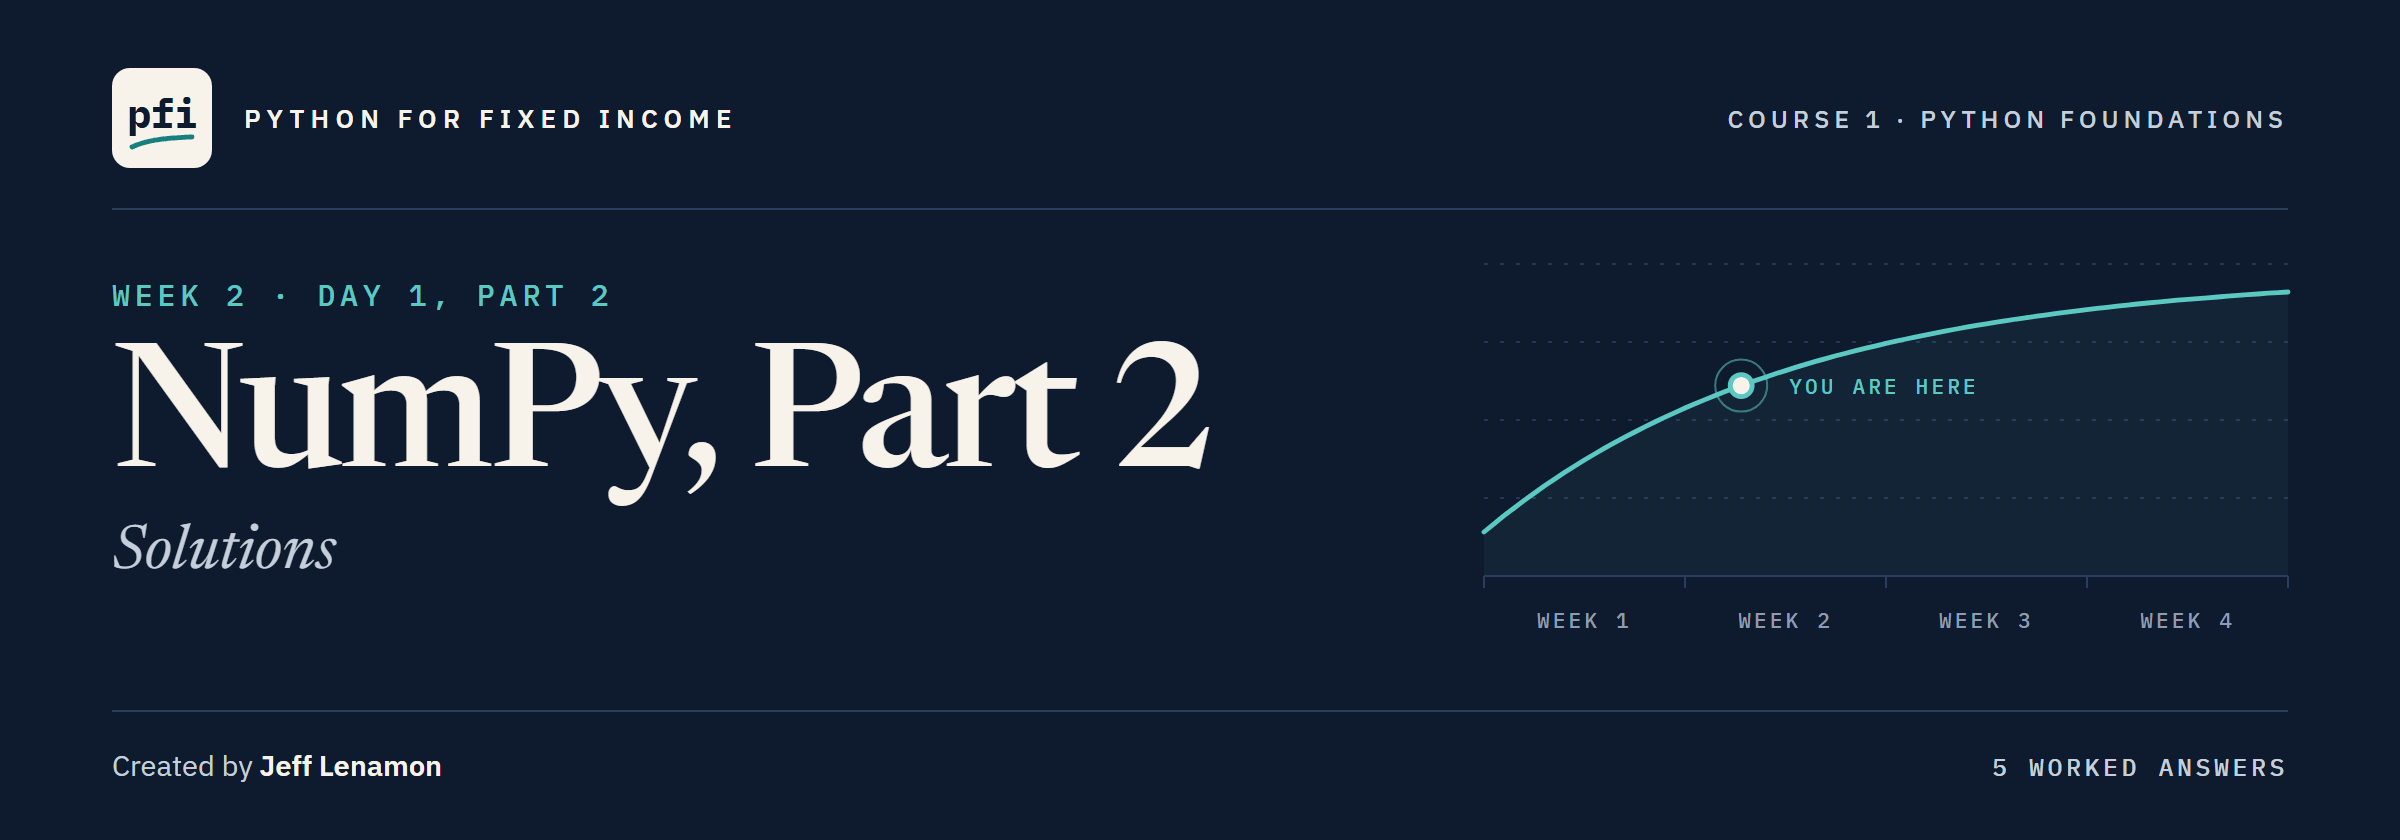

# NumPy, Part 2: Solutions

Week 2, Day 1, Part 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day1_part2/06_part2_numpy_solutions.ipynb)

## Exercises

A second desk holds three different bonds; the issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Score</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">A</td><td align="left">6</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">BBB-</td><td align="left">10</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">B</td><td align="left">15</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

These are the worked answers to the exercises in the teaching notebook; each answer is followed by its check cell.
Run the next cell first: it imports NumPy, stores the three bonds, and defines `check`.

In [1]:
import numpy as np


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    # isinstance(x, np.ndarray) is True when x is a NumPy array;
    # its .dtype.kind is 'f' when it holds decimals
    if isinstance(expected, np.ndarray) and expected.dtype.kind == 'f':
        # arrays of numbers: same shape, and every value within a small tolerance;
        # np.shape() gives the shape of a list too
        correct = np.shape(answer) == expected.shape and np.allclose(answer, expected)
    elif isinstance(expected, np.ndarray):
        # arrays of text: np.array_equal() is True for the same shape and the same values
        correct = np.array_equal(answer, expected)
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance;
        # abs() drops the sign, so this is the size of the gap between the two
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# the second desk's three bonds, one array per column
tickers = np.array(['TRNW', 'OSMC', 'CLDB'])
coupons = np.array([4.375, 5.0, 8.25])
prices = np.array([96.25, 100.0, 104.5])
faces = np.array([2000000, 1250000, 500000])
scores = np.array([6, 10, 15])

### Exercise 1

Q. Use a boolean mask to find the tickers of the bonds priced below par, and the total face held in investment grade bonds (a score of 10 or lower). Then use `np.where()` to label each bond 'Below par' when its price is under 100 and 'Par or above' otherwise. Store the answers in **ex1_below_par**, **ex1_ig_face**, and **ex1_labels**.

In [2]:
# keep the tickers where the price is under 100
ex1_below_par = tickers[prices < 100]
print('Below par:', ex1_below_par)

# keep the face amounts where the score is 10 or lower, then add them up
ex1_ig_face = faces[scores <= 10].sum()
print('Investment grade face:', ex1_ig_face)

# np.where(condition, value if True, value if False)
ex1_labels = np.where(prices < 100, 'Below par', 'Par or above')
print('Labels:', ex1_labels)

Below par: ['TRNW']
Investment grade face: 3250000
Labels: ['Below par' 'Par or above' 'Par or above']


Only TRNW is below par: OSMC is priced at exactly 100, and `prices < 100` is False for it.
TRNW and OSMC are investment grade, with 3,250,000 of face between them.
The test is `<= 10` so that OSMC, at a score of exactly 10, is included.

In [3]:
check('Exercise 1 below par', ex1_below_par, np.array(['TRNW']))
check('Exercise 1 investment grade face', ex1_ig_face, 3250000)
check('Exercise 1 labels', ex1_labels,
      np.array(['Below par', 'Par or above', 'Par or above']))

Exercise 1 below par: correct
Exercise 1 investment grade face: correct
Exercise 1 labels: correct


### Exercise 2

The second desk's risk system wants the holdings as one table in a file, not as separate columns.

Q. Build a 2-D array with one row per bond and three columns: coupon, price, and face held. Store it in **ex2_table**. Find the average of each column and store it in **ex2_column_averages**. Then save the table to a file named `second_desk_table.csv` with `np.savetxt()`, using a comma as the delimiter and three decimal places, load it back with `np.loadtxt()`, and store the loaded array in **ex2_loaded**.

In [4]:
# plain numbers instead of scientific notation
np.set_printoptions(suppress=True)

# a list of lists: each inner list is one bond
ex2_table = np.array([[4.375, 96.25, 2000000],
                      [5.0, 100.0, 1250000],
                      [8.25, 104.5, 500000]])

# axis=0 works down the rows and gives one result per column
ex2_column_averages = ex2_table.mean(axis=0)
print('Column averages:', ex2_column_averages)

# write the table as text with a comma between the columns
np.savetxt('second_desk_table.csv', ex2_table, delimiter=',', fmt='%.3f')
# read it back. There is no header line, so there are no rows to skip.
ex2_loaded = np.loadtxt('second_desk_table.csv', delimiter=',')
print(ex2_loaded)

Column averages: [      5.875     100.25  1250000.   ]
[[      4.375      96.25  2000000.   ]
 [      5.        100.    1250000.   ]
 [      8.25      104.5    500000.   ]]


The column averages are 5.875 for the coupon, 100.25 for the price, and 1,250,000 for the face.
The loaded table matches the original: three decimal places are enough, because the coupon 4.375 has exactly three.

In [5]:
check('Exercise 2 table', ex2_table,
      np.array([[4.375, 96.25, 2000000.0], [5.0, 100.0, 1250000.0], [8.25, 104.5, 500000.0]]))
check('Exercise 2 column averages', ex2_column_averages, np.array([5.875, 100.25, 1250000.0]))
check('Exercise 2 loaded', ex2_loaded,
      np.array([[4.375, 96.25, 2000000.0], [5.0, 100.0, 1250000.0], [8.25, 104.5, 500000.0]]))

Exercise 2 table: correct
Exercise 2 column averages: correct
Exercise 2 loaded: correct


### Exercise 3

The second desk's closing prices for TRNW, OSMC, and CLDB on three days arrive as one run of 9 numbers, bond by bond: 96.25, 96.5, 96.0, then 100.0, 100.2, 100.1, then 104.5, 104.0, 104.25.

Q. Lay the prices out as a grid with one row per bond and one column per day, and store it in **ex3_grid**. Use `@` to find the market value of the whole book on each day, and store it in **ex3_book_values**. Then find the log return of the book from the first day to the last day, and store it in **ex3_log_return**.

In [6]:
flat = np.array([96.25, 96.5, 96.0, 100.0, 100.2, 100.1, 104.5, 104.0, 104.25])

# 3 bonds in rows, 3 days in columns
ex3_grid = flat.reshape((3, 3))

# faces times each day's prices, summed, over 100: one value per day
ex3_book_values = faces @ ex3_grid / 100

# log return from the first day to the last day: the log of the ratio
ex3_log_return = np.log(ex3_book_values[-1] / ex3_book_values[0])

print(ex3_grid)
print('Book values:', ex3_book_values)
print('Log return, first day to last:', ex3_log_return)

[[ 96.25  96.5   96.  ]
 [100.   100.2  100.1 ]
 [104.5  104.   104.25]]
Book values: [3697500. 3702500. 3692500.]
Log return, first day to last: -0.0013531801794199703


The book is worth 3,697,500 on day one, 3,702,500 on day two, and 3,692,500 on day three.
Day one is the total cost from Part 1's Exercise 1, because the first prices are the prices the desk paid.
The log return from the first day to the last is about -0.135 percent: the book lost a little over a tenth of a percent across the three days.

In [7]:
check('Exercise 3 grid', ex3_grid, np.array([[96.25, 96.5, 96.0], [100.0, 100.2, 100.1],
                                            [104.5, 104.0, 104.25]]))
check('Exercise 3 book values', ex3_book_values, np.array([3697500.0, 3702500.0, 3692500.0]))
check('Exercise 3 log return', ex3_log_return, -0.00135318018)

Exercise 3 grid: correct
Exercise 3 book values: correct
Exercise 3 log return: correct


### Exercise 4

OSMC has a 5 percent coupon.

Give it exactly 5 years to maturity and price it per 100 of face at a yield of 6 percent, with the three assumptions of section 6.6: whole periods, semiannual compounding, and settlement on a coupon date.

Q. Build the cash flows in **ex4_cash_flows**, the discount factors in **ex4_discount_factors**, and the price in **ex4_price**.

In [8]:
# 5 years of semiannual coupons is 10 periods
ex4_periods = np.arange(1, 5 * 2 + 1)

# half of the annual coupon every period, and the 100 of principal with the last one
ex4_cash_flows = np.ones(ex4_periods.size) * 5.0 / 2
ex4_cash_flows[-1] = ex4_cash_flows[-1] + 100

# half of the annual yield applies to each period
ex4_discount_factors = 1 / (1 + 6.0 / 100 / 2) ** ex4_periods

# the price is the sum of the present values
ex4_price = (ex4_cash_flows * ex4_discount_factors).sum()

print('Cash flows:', ex4_cash_flows)
print('Discount factors:', np.round(ex4_discount_factors, 4))
print('Price:', round(ex4_price, 4))

Cash flows: [  2.5   2.5   2.5   2.5   2.5   2.5   2.5   2.5   2.5 102.5]
Discount factors: [0.9709 0.9426 0.9151 0.8885 0.8626 0.8375 0.8131 0.7894 0.7664 0.7441]
Price: 95.7349


Nine payments of 2.5 and a final payment of 102.5.
The price is 95.7349: the yield of 6 percent is above the coupon of 5 percent, so the bond is priced below par.

In [9]:
check('Exercise 4 last cash flow',
      None if ex4_cash_flows is ... else ex4_cash_flows[-1], 102.5)
check('Exercise 4 first discount factor',
      None if ex4_discount_factors is ... else ex4_discount_factors[0], 1 / 1.03)
check('Exercise 4 price', ex4_price, 95.73489858)

Exercise 4 last cash flow: correct
Exercise 4 first discount factor: correct
Exercise 4 price: correct


### Exercise 5: AI check

You ask an AI assistant for a function that prices a bond from its yield, with the assumptions of section 6.6; it has one bug.

Q. Read the code before you run it. What number do you expect? You worked out the price of OSMC at a yield of 6 percent yourself in Exercise 4. Then run the code. Does it agree with you?

The answer from Exercise 4 is 95.7349; the original code printed 74.2397, with no error.
The bug was in the discount factors: the code divided the yield by 100 and stopped, so the full annual yield was applied to every six-month period.
Half of it applies to each period: `yield_pct / 100 / 2`.
A price of about 74.2 looks like a bond at a discount, so nothing about it stood out; the check that caught it was a number worked out independently.
A second check from section 6.6: at a yield equal to the coupon the price must be 100, and the original code gave 80.70 for `ai_price(5.0, 5, 5.0)`.

In [10]:
def ai_price(coupon, years, yield_pct):
    """
    Take an annual coupon in percent, a whole number of years to maturity,
    and an annual yield in percent,
    and return the price per 100 of face.
    Assumes semiannual coupons and settlement on a coupon date.
    """
    periods = np.arange(1, years * 2 + 1)
    cash_flows = np.ones(periods.size) * coupon / 2
    cash_flows[-1] = cash_flows[-1] + 100
    # half of the annual yield applies to each period
    discount_factors = 1 / (1 + yield_pct / 100 / 2) ** periods
    return (cash_flows * discount_factors).sum()


ex5_price = ai_price(5.0, 5, 6.0)
print(f'The price of OSMC at a yield of 6 percent is {round(ex5_price, 4)}')

The price of OSMC at a yield of 6 percent is 95.7349


In [11]:
check('Exercise 5', ex5_price, 95.73489858)

Exercise 5: correct


When you are finished, run this cell to remove the file that Exercise 2 created.

In [12]:
import os

# remove the file from Exercise 2, if it was created
if os.path.exists('second_desk_table.csv'):
    os.remove('second_desk_table.csv')

print('second_desk_table.csv still there:', os.path.exists('second_desk_table.csv'))

second_desk_table.csv still there: False


[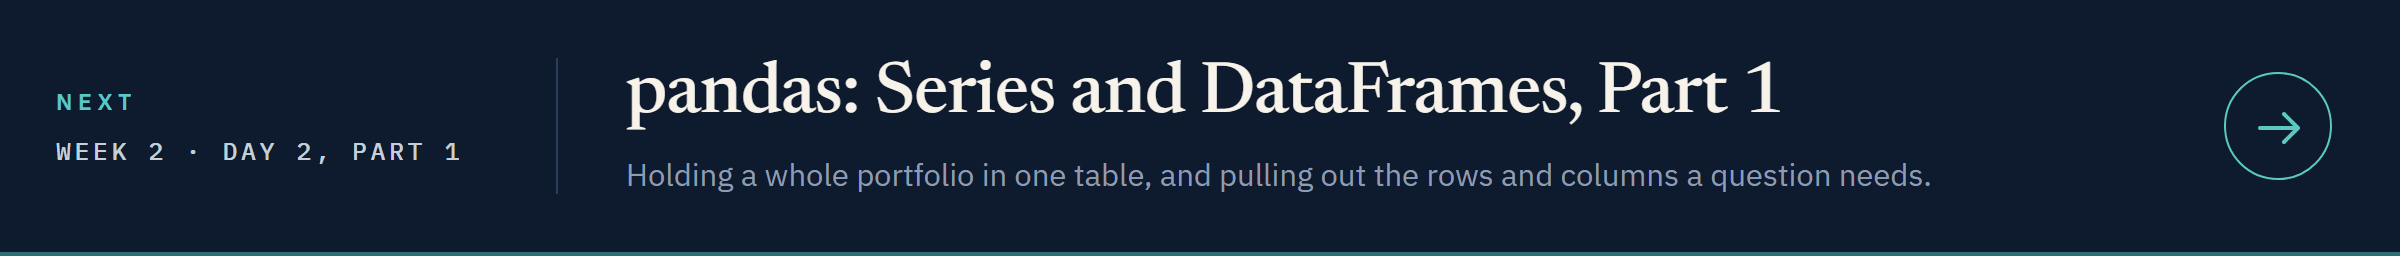](../day2/07_pandas_series_and_dataframes.ipynb)

[Open Day 2, Part 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day2/07_pandas_series_and_dataframes.ipynb)